In [ ]:
# Global Imports and Runtime Visual Configuration
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler,MinMaxScaler,RobustScaler,PowerTransformer,QuantileTransformer
# Visual styling settings
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10

print("Global libraries for categorical encoding strategies loaded successfully.")

Global libraries for categorical encoding strategies loaded successfully.


## 1. Standardization vs Min-Max Scaling

In [9]:
np.random.seed(seed=42)
x_data = np.random.normal(50,10,10).reshape(-1,1)
print(x_data)

[[54.96714153]
 [48.61735699]
 [56.47688538]
 [65.23029856]
 [47.65846625]
 [47.65863043]
 [65.79212816]
 [57.67434729]
 [45.30525614]
 [55.42560044]]


In [ ]:
scaler_std = StandardScaler() # mean = 0 and std = 1 : scales standard normal distribution
scaler_mm = MinMaxScaler() # min = 0 and max = 1 : scales fixed and bounded range

df_scaled = pd.DataFrame({
    'Standaredized':scaler_std.fit_transform(x_data).flatten(),
    'MinMax':scaler_mm.fit_transform(x_data).flatten()
})
print("Scaled Data Summary Statistics:\n",
      df_scaled.describe().round(2))

Scaled Data Summary Statistics:
        Standaredized  MinMax
count          10.00   10.00
mean            0.00    0.45
std             1.05    0.35
min            -1.34    0.00
25%            -0.96    0.13
50%             0.10    0.48
75%             0.42    0.59
max             1.65    1.00


## 2. Robust scaler for Outlier-Heavy Data

In [14]:
x_outliers = np.concatenate([np.random.normal(0,1,90),[2025,-22]]) #Contains outliers
scaler_rob = RobustScaler()
x_rob = scaler_rob.fit_transform(x_outliers.reshape(-1,1)).flatten()

print("Robust Scaler Output Summary:",round(x_rob.min()),round(x_rob.max()))

Robust Scaler Output Summary: -16 1446


Original Skew vs Transformed skew:  1.38 -> 0.08


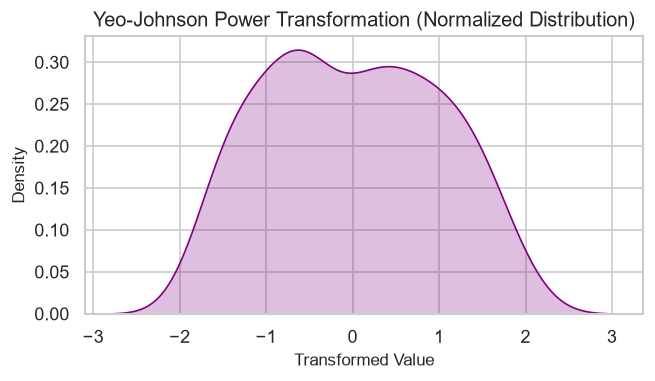

In [21]:
np.random.seed(seed=42)
skewed_data = np.random.exponential(scale = 2, size = 200).reshape(-1,1)
pt = PowerTransformer(method='yeo-johnson')
transformed_data = pt.fit_transform(skewed_data)

print("Original Skew vs Transformed skew: ",
      round(pd.Series(skewed_data.flatten()).skew(),2),
      "->", 
      round(pd.Series(transformed_data.flatten()).skew(),2))
# Visualization
plt.figure(figsize=(6, 3))
sns.kdeplot(transformed_data.flatten(), color='purple', fill=True)
plt.title('Yeo-Johnson Power Transformation (Normalized Distribution)')
plt.xlabel('Transformed Value')
plt.show()


## 4. Quantile Uniform and Normal Transform